# 04 · What-if experiments

The question most people bring to a retirement model is not "will my plan work?" but "what
changes the answer?" This notebook takes one **fictional** household and changes one thing at a
time: when they retire, how much they spend, when they claim Social Security, how a pension is
indexed, and how many years of part-time work bridge the gap. Each experiment is a small table
and a chart.

Every experiment is the same three steps, which you can copy for your own plan:

1. write the plan as a [plan file](https://github.com/madisonicus/firebridgelab/blob/main/docs/plan-files.md)
   (here, a string; normally a `.toml` file),
2. change one key with `apply_override`, the function behind the command line's `--set`,
3. run the historical replay and Monte Carlo, and keep the headline numbers.

The command line does the same with `firebridgelab sweep plan.toml --set key=v1,v2,...`.

**How to read the numbers.** *Historical success* is the share of every retirement since 1871
(Shiller data) in which the portfolio lasted to the end of the plan. The cohorts overlap
heavily, so it is a count of past outcomes, not a probability. *Monte Carlo success* is the
same share over 2,000 randomly drawn return paths with the historical mean and volatility.
*Median end* is the median portfolio left at the end, in today's dollars.

*Educational software, not financial advice.*

In [1]:
import copy
import tomllib

import matplotlib.pyplot as plt
import pandas as pd

from firebridgelab.cli.outcomes import run_outcome
from firebridgelab.plan import apply_override, from_document

plt.rcParams.update({"figure.dpi": 90, "figure.figsize": (9, 4)})
pd.set_option("display.width", 160)

## The household

Alex (50) and Blake (48) stop full-time work this year with $1.5M. Alex has a deferred
pension of $20,000 a year from 60, fixed in dollars until it starts and then indexed FERS-style.
Both claim Social Security at 67. Blake could do some part-time work; in the base plan, none.
They budget $72,000 a year plus $12,000 a year of marketplace health insurance until Alex
reaches Medicare at 65 (required spending, which the spending rule cannot cut).

In [2]:
BASE_PLAN = """
name = "What-if base"

[[people]]
name = "Alex"
start_age = 50
end_age = 95

[[people]]
name = "Blake"
start_age = 48
end_age = 95

[[income_streams]]
id = "alex_pension"
kind = "pension"
owner = "a"
amount = 20_000
start_age = 60
nominal_until_start = true
cola = "fers_diet"
survivor_fraction = 0.5

[[income_streams]]
id = "alex_ss"
kind = "social_security"
owner = "a"
amount = 28_000          # at full retirement age (67)
start_age = 67           # claim age

[[income_streams]]
id = "blake_ss"
kind = "social_security"
owner = "b"
amount = 22_000
start_age = 67

[[income_streams]]
id = "blake_part_time"
kind = "work"
owner = "b"
amount = 0               # none in the base plan
start_age = 48
end_age = 49

[[spending_adjustments]]
id = "aca"
owner = "household"
amount = 12_000
start_age = 50
end_age = 65

[portfolio]
balance = 1_500_000

[allocation]
weights = { us_total_market = 0.6, us_agg_bonds = 0.4 }

[spending]
annual = 72_000
rule = "constant"

[simulation]
trials = 2_000
"""

BASE = tomllib.loads(BASE_PLAN)


def plan_with(**changes):
    """The base plan with dotted keys changed, e.g. plan_with(**{"spending.annual": 80000})."""
    doc = copy.deepcopy(BASE)
    for key, value in changes.items():
        apply_override(doc, key, value)
    return from_document(doc, "what-if")


def headline(label, plan):
    hist = run_outcome(plan, "historical")
    mc = run_outcome(plan, "monte_carlo")
    return {
        "variant": label,
        "historical success %": round(100 * hist.success_rate, 1),
        "Monte Carlo success %": round(100 * mc.success_rate, 1),
        "earliest depletion (hist)": hist.earliest_depletion_age,
        "median end $k (hist)": round(hist.terminal[1] / 1e3),
    }


def table(rows):
    df = pd.DataFrame(rows).set_index("variant")
    df["earliest depletion (hist)"] = df["earliest depletion (hist)"].astype("Int64")
    return df


def sweep(label_fmt, key, values, **fixed):
    return table([headline(label_fmt.format(v), plan_with(**{key: v}, **fixed)) for v in values])


def success_chart(df, title, xlabel, kind="line"):
    style = {"marker": "o"} if kind == "line" else {}
    ax = df[["historical success %", "Monte Carlo success %"]].plot(kind=kind, rot=0, **style)
    ax.set_ylim(0, 100); ax.set_ylabel("plans that last, %"); ax.set_xlabel(xlabel)
    ax.set_title(title); ax.grid(alpha=0.3)
    plt.show()


table([headline("base plan", plan_with())])

,historical success %,Monte Carlo success %,earliest depletion (hist),median end $k (hist)
variant,,,,
base plan,93.5,96.1,66,4345


## 1. Retirement age

Retiring later does three things at once: fewer years for the portfolio to fund, more years of
saving, and less time until the pension and Social Security arrive. To keep the experiment
honest we spell out the saving: each extra year of full-time work adds **$40,000** to the
portfolio, which also earns a modest **3% real** while they work. Both stop together, the
health-insurance years shrink, and every income stream keeps its age.

In [3]:
def retire_at(age_a):
    # The plan-file changes for Alex retiring at age_a (Blake two years younger).
    years = age_a - 50
    balance = 1_500_000 * 1.03 ** years + 40_000 * sum(1.03 ** k for k in range(years))
    return {
        "people.a.start_age": age_a,
        "people.b.start_age": age_a - 2,
        "income_streams.blake_part_time.start_age": age_a - 2,
        "income_streams.blake_part_time.end_age": age_a - 1,
        "spending_adjustments.aca.start_age": age_a,
        "portfolio.balance": round(balance),
    }

rows = []
for age in (50, 52, 54, 56, 58):
    changes = retire_at(age)
    r = headline(f"retire at {age}", plan_with(**changes))
    r["portfolio at retirement $k"] = round(changes["portfolio.balance"] / 1e3)
    rows.append(r)
retire = table(rows)
retire

,historical success %,Monte Carlo success %,earliest depletion (hist),median end $k (hist),portfolio at retirement $k
variant,,,,,
retire at 50,93.5,96.1,66,4345,1500
retire at 52,100.0,99.6,<NA>,6063,1673
retire at 54,100.0,100.0,<NA>,7960,1856
retire at 56,100.0,100.0,<NA>,9559,2050
retire at 58,100.0,100.0,<NA>,10621,2256


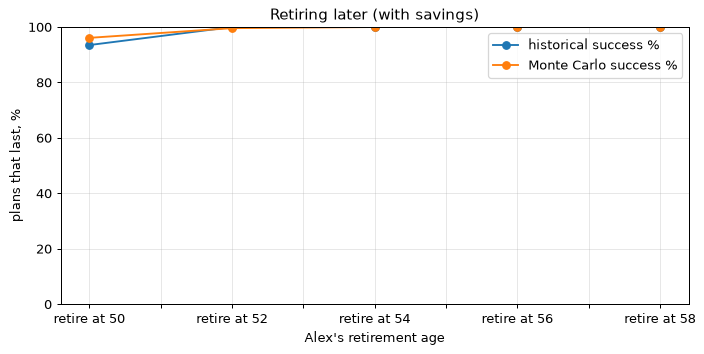

In [4]:
success_chart(retire, "Retiring later (with savings)", "Alex's retirement age")

## 2. Spending

The single most powerful lever. Health insurance stays on top of the amount shown.

In [5]:
spend = sweep("${:,} a year", "spending.annual", range(56_000, 96_001, 8_000))
spend

,historical success %,Monte Carlo success %,earliest depletion (hist),median end $k (hist)
variant,,,,
"$56,000 a year",100.0,99.9,<NA>,7662
"$64,000 a year",100.0,99.2,<NA>,5948
"$72,000 a year",93.5,96.1,66,4345
"$80,000 a year",82.4,89.3,63,2929
"$88,000 a year",64.8,77.4,61,1400
"$96,000 a year",50.9,64.5,60,109


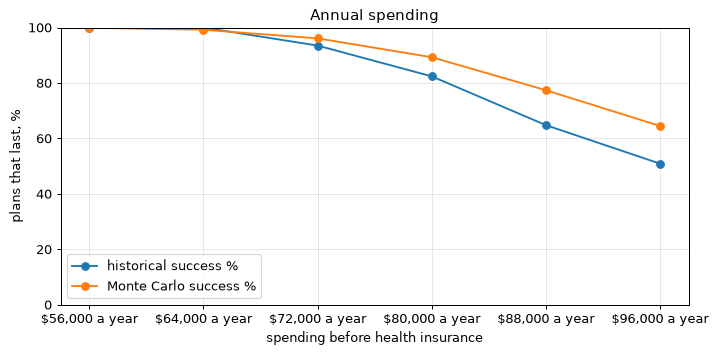

In [6]:
success_chart(spend, "Annual spending", "spending before health insurance")

### Spending and retirement age together

Two levers at once, historical success only. Read across a row to see what retiring later buys
at one spending level.

In [7]:
grid = {}
for age in (50, 53, 56):
    for annual in (64_000, 72_000, 80_000, 88_000):
        plan = plan_with(**retire_at(age), **{"spending.annual": annual})
        grid[(f"${annual:,}", f"retire at {age}")] = round(
            100 * run_outcome(plan, "historical").success_rate, 1)
heat = pd.Series(grid).unstack()
heat

,retire at 50,retire at 53,retire at 56
"$64,000",100.0,100.0,100.0
"$72,000",93.5,100.0,100.0
"$80,000",82.4,100.0,100.0
"$88,000",64.8,97.3,100.0


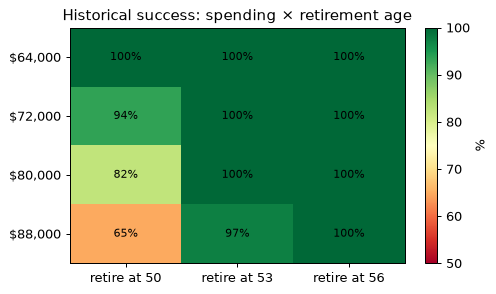

In [8]:
fig, ax = plt.subplots(figsize=(6, 3.4))
im = ax.imshow(heat.values, cmap="RdYlGn", vmin=50, vmax=100, aspect="auto")
ax.set_xticks(range(len(heat.columns)), heat.columns)
ax.set_yticks(range(len(heat.index)), heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat.values[i, j]:.0f}%", ha="center", va="center", fontsize=9)
ax.set_title("Historical success: spending × retirement age")
fig.colorbar(im, ax=ax, label="%")
plt.show()

## 3. Social Security claim age

Each person's claim age moves their benefit by the SSA's own factors: 70% of the full
benefit at 62, 100% at 67, 124% at 70. Claiming later means a bigger check for life but more
years the portfolio pays alone. Here both claim at the same age.

In [9]:
claim = table([
    headline(f"both claim at {age}", plan_with(**{
        "income_streams.alex_ss.start_age": age, "income_streams.blake_ss.start_age": age}))
    for age in (62, 64, 67, 70)
])
claim

,historical success %,Monte Carlo success %,earliest depletion (hist),median end $k (hist)
variant,,,,
both claim at 62,96.3,95.5,78,3951
both claim at 64,95.4,95.7,72,4062
both claim at 67,93.5,96.1,66,4345
both claim at 70,93.5,96.0,66,4429


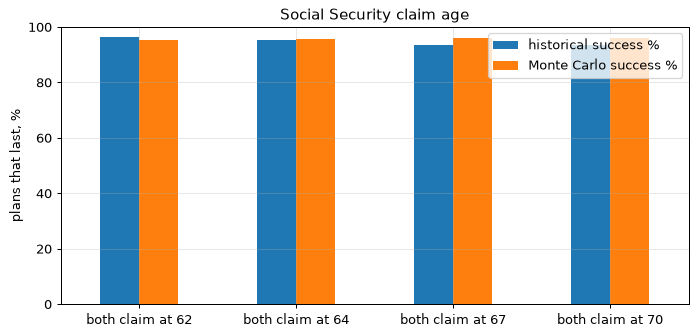

In [10]:
success_chart(claim, "Social Security claim age", "", kind="bar")

## 4. How the pension is indexed

Alex's pension is $20,000 a year. Whether that is today's dollars or the dollar check at 60,
and how it keeps up with inflation afterwards, changes what it is worth. `cola` is the
cost-of-living rule: `full` keeps its real value, `fers_diet` trails inflation (CPI up to 2%,
2% for CPI of 2-3%, CPI - 1% above that), `fixed` adds a fixed nominal rate, and `none` is
fixed in dollars forever. With `nominal_until_start` the amount is the check at 60, eroded by
2.5% inflation until then.

In [11]:
cola_cases = {
    "full CPI, today's dollars": {"income_streams.alex_pension.cola": "full",
                                  "income_streams.alex_pension.nominal_until_start": False},
    "full CPI, fixed until 60": {"income_streams.alex_pension.cola": "full"},
    "FERS diet, fixed until 60 (base)": {},
    "1% fixed COLA, fixed until 60": {"income_streams.alex_pension.cola": "fixed",
                                      "income_streams.alex_pension.cola_rate": 0.01},
    "no COLA, fixed until 60": {"income_streams.alex_pension.cola": "none"},
}
cola = table([headline(name, plan_with(**ch)) for name, ch in cola_cases.items()])
cola

,historical success %,Monte Carlo success %,earliest depletion (hist),median end $k (hist)
variant,,,,
"full CPI, today's dollars",98.1,97.8,68,4937
"full CPI, fixed until 60",96.3,96.5,66,4451
"FERS diet, fixed until 60 (base)",93.5,96.1,66,4345
"1% fixed COLA, fixed until 60",93.5,95.5,66,4139
"no COLA, fixed until 60",93.5,95.2,66,3966


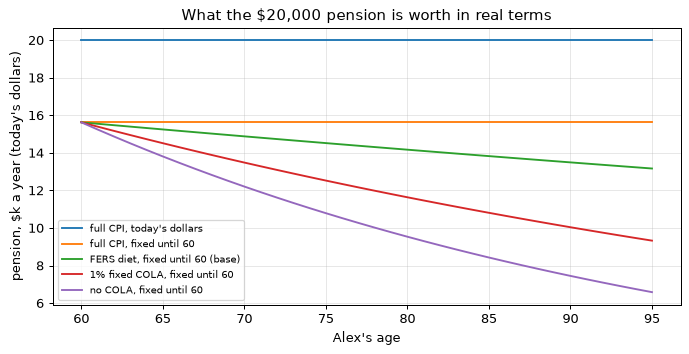

In [12]:
import firebridgelab as rm

ages = range(60, 96)
fig, ax = plt.subplots()
for name, ch in cola_cases.items():
    s = plan_with(**ch).scenario
    only = rm.with_household(s, people=s.people,
                             income_streams=[st for st in s.income_streams if st.id == "alex_pension"],
                             cash_events=(), spending_adjustments=())
    ax.plot(list(ages), [rm.gi_at_age(only, a) / 1e3 for a in ages], label=name)
ax.set_xlabel("Alex's age"); ax.set_ylabel("pension, $k a year (today's dollars)")
ax.set_title("What the $20,000 pension is worth in real terms")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.show()

## 5. Years of part-time work

Blake earns $25,000 a year part time from 48, for a few years or none. Each year of work is a
year the portfolio does not have to fund in full, at the start of the plan when a bad market
hurts most.

In [13]:
rows = [headline("no part-time work", plan_with())]
for years in (2, 4, 6, 8):
    rows.append(headline(f"{years} years part time", plan_with(**{
        "income_streams.blake_part_time.amount": 25_000,
        "income_streams.blake_part_time.end_age": 48 + years})))
part_time = table(rows)
part_time

,historical success %,Monte Carlo success %,earliest depletion (hist),median end $k (hist)
variant,,,,
no part-time work,93.5,96.1,66,4345
2 years part time,96.3,97.2,75,4720
4 years part time,100.0,97.7,<NA>,5097
6 years part time,100.0,98.1,<NA>,5481
8 years part time,100.0,98.6,<NA>,5954


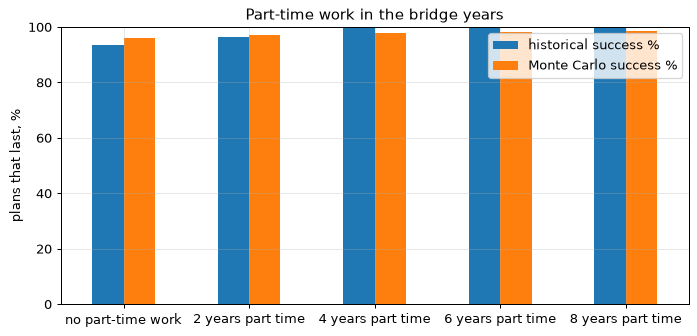

In [14]:
success_chart(part_time, "Part-time work in the bridge years", "", kind="bar")

## What to take from this

- For this household, spending and the first few years matter most: a few years of part-time
  income or a slightly later retirement moves the historical success rate more than any
  pension or claiming detail.
- Claiming Social Security later raises the benefit but lengthens the bridge. Whether it pays
  depends on how long the portfolio has to carry the gap; the table shows the trade for this
  plan, not a rule.
- A pension's indexing terms change its real value by tens of percent over a retirement.
  Read the plan document for how yours is adjusted, and enter it per stream.
- Historical and Monte Carlo rates differ because Monte Carlo has no long runs of bad
  years like 1966-1982. Use both as ranges, not as the odds.

To run the same experiments on your own numbers: `firebridgelab init plan.toml`, edit the file,
then `firebridgelab sweep plan.toml --set spending.annual=60000:90000:10000`. Or change
`BASE_PLAN` above and rerun this notebook.